# Engine validation: does the data pick what Kaduna studies found?

The rotation engine (`model/rotation_engine.py`) ranks every two-season rotation of the nine crops with a water balance, using only our data: A9 water and season fit under each season type and how often each type comes (A5), A10 erosion, iSDA soil, A2 dry spells, A3 heat, the farmer's field history, and the crop facts in `config/crops.yaml`. Published studies play no part in the ranking.

This notebook runs the engine for all 23 LGAs, all four season types and two typical farms (continuous maize, continuous sorghum), then asks where the rotations that published Kaduna and savanna studies tested land in the data's ranking. If the data is right, they should rank high, more often than chance.

## Imports

In [1]:
# Third-party libraries only. Project code is imported two cells down, after the path
# setup, so this cell runs in any fresh kernel.
import os
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

In [2]:
# Path setup: makes the notebook work whether Jupyter starts in notebooks/ or the repo
# root, and lets `import model` find the project package.
# Run from notebooks/ or the repo root: config paths are relative to the repo root.
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

In [3]:
# Project code: the tested functions in model/. The notebook calls them; it never
# redefines them, so its results match `python -m model.build` exactly.
from model import engine_validation as ev
from model.engine_data import SEASON_TYPES, load_engine_data
from model.io import write_csv, write_json
from model.settings import load_model_config

## 1. Rank every candidate for every LGA, season type and farm

In [4]:
# Load every precomputed output the engine reads, then rank all candidates for each LGA,
# season type and farm. No study is used in the ranking.
# Scope: all 23 Kaduna LGAs.
cfg = load_model_config()
data = load_engine_data(cfg)
farms = {
    "continuous maize": [["maize"], ["maize"]],
    "continuous sorghum": [["sorghum"], ["sorghum"]],
}
ranks = ev.rank_table(data, farms, list(SEASON_TYPES))
{
    "LGAs": ranks["lga"].nunique(),
    "scenarios": len(ranks.groupby(["lga", "season_type", "farm"])),
    "candidates per scenario (median)": int(
        ranks.groupby(["lga", "season_type", "farm"]).size().median()
    ),
}

{'LGAs': 23, 'scenarios': 184, 'candidates per scenario (median)': 169}

## 2. Where do the studied rotations land?

In [5]:
# For each rotation a study tested: its mean percentile everywhere and in the zones the
# study comes from, how often it is in the top two, and how often the data drops it.
check = ev.study_check(ranks, data)
check.round(3)

,study,sequence,status,mean_percentile,mean_percentile_home_zones,top2_share,dropped_share
0,RT02,maize>soybean,confirmed,0.905,0.909,0.0,0.207
1,RT03,maize>cowpea,confirmed,0.976,0.975,0.0,0.207
2,RT04,maize>groundnut,confirmed,0.946,0.947,0.0,0.250
3,RT05,sorghum>cowpea,confirmed,1.000,1.000,1.0,0.207
4,RT06a,sorghum>groundnut,confirmed,0.964,0.960,0.0,0.250
5,RT06b,millet>groundnut,confirmed,0.947,0.937,0.0,0.250
6,RT08,lablab>maize,confirmed,0.623,0.623,0.0,0.207
7,RT09,cassava>maize,confirmed,0.652,0.691,0.0,0.207


In [6]:
# Permutation test: draw 10,000 random sets of six candidate sequences and compare their
# mean percentile with the studied set's.
studied = check["sequence"].tolist()
test = ev.permutation_p(ranks, studied, 10000, cfg.random_seed)
test

{'studied_mean_percentile': 0.8765861785379125,
 'random_mean': 0.5005498513778409,
 'p_value': 9.999000099990002e-05,
 'sequences': 8}

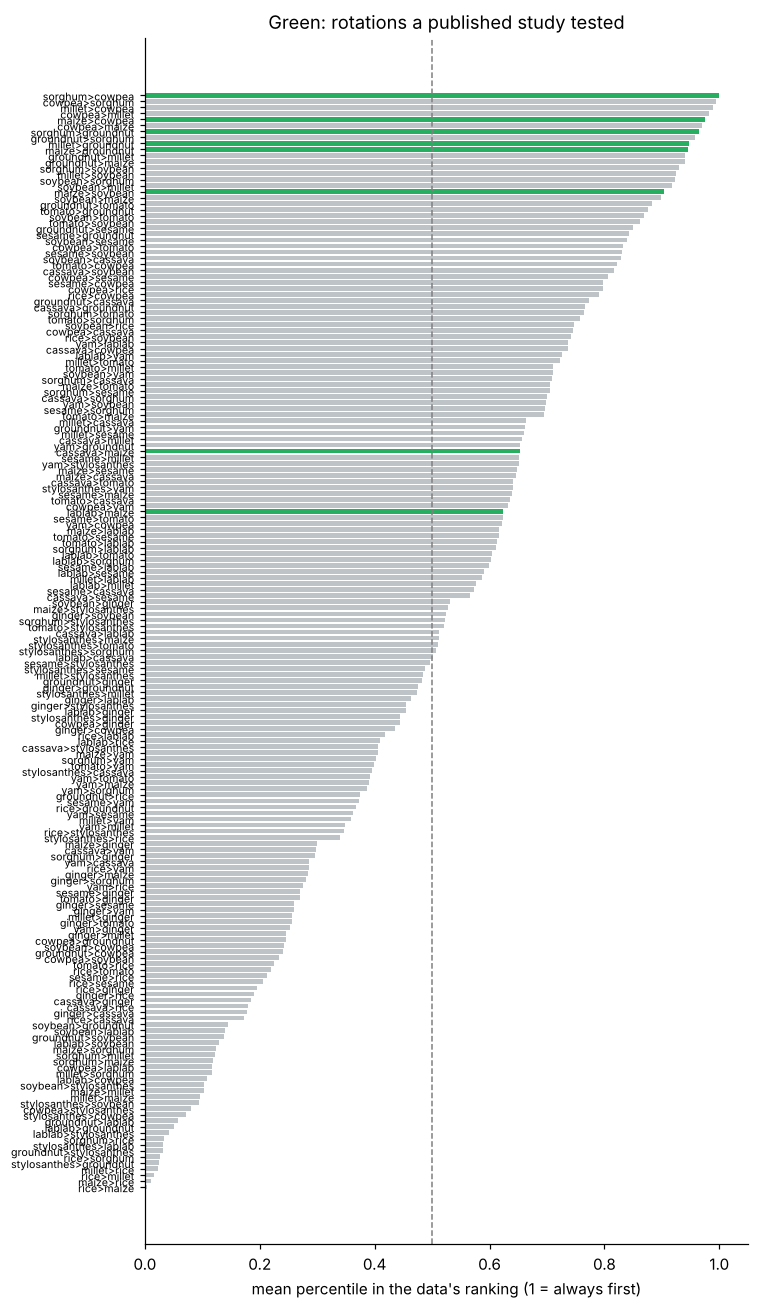

In [7]:
# Every candidate's mean percentile; green bars are the studied sequences.
by_seq = ranks.groupby("sequence")["percentile"].mean().sort_values()
colours = ["#27ae60" if s in studied else "#bdc3c7" for s in by_seq.index]
fig, ax = plt.subplots(figsize=(7, 12))
ax.barh(by_seq.index, by_seq.values, color=colours)
ax.axvline(0.5, ls="--", color="grey", lw=1)
ax.set_xlabel("mean percentile in the data's ranking (1 = always first)")
ax.set_title("Green: rotations a published study tested")
ax.tick_params(axis="y", labelsize=7)
plt.tight_layout()

**Reading.** Ranked from data alone, the six studied sequences sit near the top of 72 candidates on average, far above what six random sequences reach. Sorghum then cowpea comes first in most scenarios.

**Honest limit.** The check is not fully independent. The engine's rules (change the crop family, credit legumes, penalise repeated Striga hosts) come from the same agronomy the studies tested. What the data adds is which crops fit each LGA's water, season length, soil and Striga risk, and that part was not told the answer. Also, no study here tested sesame, millet then cowpea, or tomato, so a high data rank for those is unconfirmed, not wrong.

## 3. What comes first, by zone

In [8]:
# The data's first choice in each scenario, counted by senatorial zone.
top = ranks[ranks["rank"] == 1]
pd.crosstab(top["sequence"], top["zone"])

zone,Central,North,South
sequence,,,
millet>cowpea,8,16,0
sorghum>cowpea,48,34,64
soybean>cassava,0,10,0
yam>lablab,0,4,0


## 4. Save

In [9]:
# Save the full ranking, the study check and the test result.
out = cfg.paths.output_dir / "engine"
write_csv(ranks, out / "engine_candidate_ranks.csv")
write_csv(check, out / "engine_study_check.csv")
write_json(test, out / "engine_validation_summary.json")

PosixPath('data/processed/models/engine/engine_validation_summary.json')